# Kettle Logic: can language models tell a fallacy from irony?

Each model reads a short passage and answers in three steps, in one conversation:

1. **First answer:** pick an option, give a probability for every option, and quote the sentences that support it.
2. **Another reading?** Say whether a different option could be defended, quote the evidence for it, and say how likely that reading is.
3. **Final answer:** choose again, with probabilities.

The 31 passages mix everyday arguments, literary passages (Aesop to Chekhov), retellings of one argument in new settings, and look-alikes that resemble kettle logic but are not. All literary passages are paraphrases of public-domain works.

Every passage has five options. Option E is always "None of the statements above gives a correct description of the reasoning in this passage." On **10 of the 31** passages the correct statement was removed and replaced with a new wrong one, so E is the right answer there.

This notebook reads the exported results (`assets/kettle-logic/results.json`) and reproduces every number in the report.

In [1]:
import json
from collections import Counter
from difflib import SequenceMatcher
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

pd.set_option("display.max_colwidth", 120)
DATA = json.loads(Path("../assets/kettle-logic/results.json").read_text(encoding="utf-8"))
MODELS = {m["key"]: m for m in DATA["models"]}
ITEMS = DATA["items"]
print(f"{len(ITEMS)} passages, models: {', '.join(m['label'] for m in DATA['models'])}")

31 passages, models: Ministral 3B, Ministral 8B, Ministral 14B


## The dataset

In [2]:
items = pd.DataFrame([{k: it[k] for k in ("id", "name", "group", "ambiguity", "correct", "answer_in_options")} for it in ITEMS])
display(pd.crosstab(items["group"], items["ambiguity"], margins=True))
print("Correct answers by letter:", dict(sorted(Counter(items["correct"]).items())))
print("Passages with no correct option (answer E):", (~items["answer_in_options"]).sum())

ambiguity,high,low,medium,All
group,,,,
Everyday cases,0,7,2,9
Literary passages,2,5,8,15
Look-alikes and controls,1,2,1,4
Retellings,0,3,0,3
All,3,17,11,31


Correct answers by letter: {'A': 5, 'B': 5, 'C': 6, 'D': 5, 'E': 10}
Passages with no correct option (answer E): 10


Correct answers are spread evenly across A–D. All options were rewritten to 80–100 characters, because in the first draft
picking the longest option was right on **31 of 31** items. The check below confirms that length now gives nothing away.

In [3]:
def length_shortcut(items):
    hits = 0.0
    for it in items:
        lens = {k: len(v) for k, v in it["options"].items()}
        top = max(lens.values())
        winners = [k for k, v in lens.items() if v == top]
        hits += (it["correct"] in winners) / len(winners)
    return hits

print(f"'Pick the longest option' scores {length_shortcut(ITEMS):.1f} / {len(ITEMS)} (chance with five options: {len(ITEMS)/5:.1f})")

'Pick the longest option' scores 4.0 / 31 (chance with five options: 6.2)


## The protocol
The exact prompts for one passage:

In [4]:
for i, p in enumerate(DATA["protocol"]["prompts"], 1):
    print(f"--- turn {i} ---\n{p}\n")

--- turn 1 ---
Passage:
When Elena noticed that the book was missing from the library, she immediately suspected Daniel. She knew he had borrowed books before and sometimes forgot to return them. Besides, Daniel had told her that he disliked the author, which meant he probably had no reason to steal the book. In any case, he could not have taken it because he had been seen leaving the library before the book disappeared. Elena concluded that Daniel must have taken it because he had both the opportunity and no reason to take it.

Question: Which statement best describes the reasoning in this passage?

Options:
A. The evidence, taken together, conclusively establishes that Daniel took the book.
B. Several independent pieces of evidence each establish on their own that Daniel is guilty.
C. Reasons that count against Daniel's guilt are used as support for it, alongside the others.
D. Daniel's history of borrowing books proves that he intended to steal this particular one.
E. None of the st

## Scoring
One row per model and passage.

In [5]:
def norm(t):
    t = t.replace("\u2019", "'").replace("\u2018", "'").replace("\u201c", '"').replace("\u201d", '"').replace("\u2014", "-")
    return " ".join(t.lower().split()).strip(" .,'\"")

rows = []
for it in ITEMS:
    for key, r in it["responses"].items():
        first, alt, final = r["first"], r["alternative"], r["final"]
        quotes = first["evidence"] + alt["evidence"]
        alt_choice = alt["choice"] if alt["exists"] else None
        rows.append({
            "model": MODELS[key]["label"], "id": it["id"], "name": it["name"], "group": it["group"],
            "ambiguity": it["ambiguity"], "correct": it["correct"], "first": first["choice"], "final": final["choice"],
            "answer_listed": it["answer_in_options"], "alt_choice": alt_choice,
            "first_correct": first["choice"] == it["correct"], "final_correct": final["choice"] == it["correct"],
            "changed": first["choice"] != final["choice"],
            "confidence": first["probabilities"][first["choice"]],
            "p_correct_final": final["probabilities"][it["correct"]],
            "brier": sum((final["probabilities"][k] - (k == it["correct"])) ** 2 for k in "ABCDE"),
            "alt_raised": alt_choice is not None and alt_choice != first["choice"],
            "alt_rescues": alt_choice == it["correct"] and first["choice"] != it["correct"],
            "quotes": len(quotes),
            "quotes_exact": sum(q["status"] == "exact" for q in quotes),
            "quotes_missing": sum(q["status"] == "not found" for q in quotes),
        })
df = pd.DataFrame(rows)
model_order = [m["label"] for m in DATA["models"]]
df["model"] = pd.Categorical(df["model"], model_order, ordered=True)
df.head()

,model,id,name,group,ambiguity,correct,first,final,answer_listed,alt_choice,...,final_correct,changed,confidence,p_correct_final,brier,alt_raised,alt_rescues,quotes,quotes_exact,quotes_missing
0,Ministral 14B,0,The missing book,Everyday cases,low,C,C,C,True,A,...,True,False,0.700000,0.65,0.160,True,False,4,4,0
1,Ministral 3B,0,The missing book,Everyday cases,low,C,C,C,True,B,...,True,False,0.818182,0.65,0.165,True,False,2,0,2
2,Ministral 8B,0,The missing book,Everyday cases,low,C,C,C,True,A,...,True,False,0.750000,0.80,0.050,True,False,8,8,0
3,Ministral 14B,1,The broken window,Everyday cases,low,E,E,E,False,A,...,True,False,0.555556,0.60,0.205,True,False,5,5,0
4,Ministral 3B,1,The broken window,Everyday cases,low,E,E,E,False,D,...,True,False,0.700000,0.65,0.190,True,False,2,1,1


## Headline numbers

In [6]:
summary = df.groupby("model", observed=True).agg(
    first_accuracy=("first_correct", "mean"),
    final_accuracy=("final_correct", "mean"),
    changed=("changed", "sum"),
    mean_confidence=("confidence", "mean"),
    brier_final=("brier", "mean"),
    offered_alternative=("alt_raised", "mean"),
    quotes=("quotes", "sum"),
    quotes_exact=("quotes_exact", "sum"),
)
summary["quotes_exact"] = summary["quotes_exact"] / summary["quotes"]
summary.drop(columns="quotes").style.format({c: "{:.0%}" for c in ["first_accuracy", "final_accuracy", "mean_confidence", "offered_alternative", "quotes_exact"]} | {"brier_final": "{:.3f}"})

,first_accuracy,final_accuracy,changed,mean_confidence,brier_final,offered_alternative,quotes_exact
model,,,,,,,
Ministral 3B,81%,74%,2,77%,0.446,90%,16%
Ministral 8B,84%,84%,0,79%,0.263,100%,89%
Ministral 14B,90%,90%,0,71%,0.214,100%,96%


## Passages with no correct option
On 10 passages the correct statement was removed, so the right answer is E. Does each model notice that nothing fits, and how sure is it when it picks one of the wrong statements anyway?

In [7]:
df["status"] = df["answer_listed"].map({True: "correct option listed", False: "no correct option"})
tab = df.pivot_table(index="status", columns="model", values="final_correct", aggfunc="mean", observed=True)
display(tab.style.format("{:.0%}").set_caption("Final answer correct"))
conf = df.pivot_table(index="status", columns="model", values="confidence", aggfunc="mean", observed=True)
display(conf.style.format("{:.0%}").set_caption("Probability given to the first choice"))
none = df[~df["answer_listed"]]
print("Chose E when E was wrong:", df[df["answer_listed"] & (df["final"] == "E")].groupby("model", observed=True).size().to_dict())
none.pivot_table(index="name", columns="model", values="final", aggfunc="first", observed=True)

model,Ministral 3B,Ministral 8B,Ministral 14B
status,,,
correct option listed,76%,95%,100%
no correct option,70%,60%,70%


model,Ministral 3B,Ministral 8B,Ministral 14B
status,,,
correct option listed,78%,82%,75%
no correct option,73%,72%,64%


Chose E when E was wrong: {'Ministral 3B': 3}


model,Ministral 3B,Ministral 8B,Ministral 14B
name,,,
A modest proposal (Swift),E,E,E
The borrowed sewing machine,E,C,C
The broken window,E,E,E
The failed experiment,E,E,E
The fox and the grapes (Aesop),E,E,E
The gravediggers (Shakespeare),E,D,D
The mysterious disappearance,B,E,E
The polluted river,E,E,E
The windmills (Cervantes),D,B,E


In [8]:
# When a model picked a wrong statement on a no-answer passage: how sure was it, and was E its alternative?
missed = none[none["first"] != "E"][["model", "name", "first", "confidence", "alt_choice"]]
missed.sort_values(["name", "model"]).style.format({"confidence": "{:.0%}"})

,model,name,first,confidence,alt_choice
20,Ministral 8B,The borrowed sewing machine,C,75%,E
18,Ministral 14B,The borrowed sewing machine,C,70%,D
38,Ministral 8B,The gravediggers (Shakespeare),D,60%,A
36,Ministral 14B,The gravediggers (Shakespeare),D,35%,B
10,Ministral 3B,The mysterious disappearance,B,82%,E
43,Ministral 3B,The windmills (Cervantes),D,70%,C
44,Ministral 8B,The windmills (Cervantes),B,85%,D
46,Ministral 3B,You have been in Afghanistan (Conan Doyle),D,60%,A
47,Ministral 8B,You have been in Afghanistan (Conan Doyle),A,90%,D
45,Ministral 14B,You have been in Afghanistan (Conan Doyle),A,85%,E


## Accuracy by type of passage

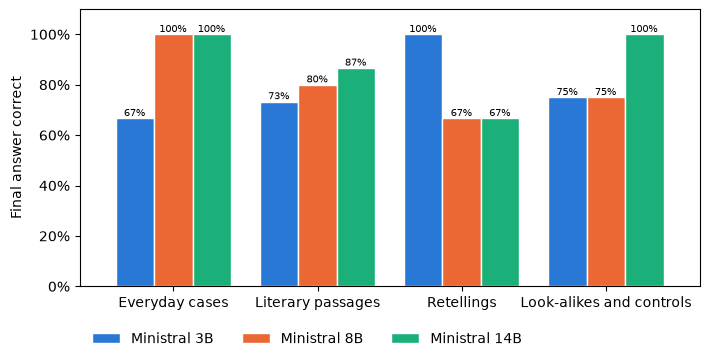

model,Ministral 3B,Ministral 8B,Ministral 14B
group,,,
Everyday cases,67%,100%,100%
Literary passages,73%,80%,87%
Retellings,100%,67%,67%
Look-alikes and controls,75%,75%,100%


In [9]:
acc = df.pivot_table(index="group", columns="model", values="final_correct", aggfunc="mean", observed=True)
acc = acc.reindex(["Everyday cases", "Literary passages", "Retellings", "Look-alikes and controls"])
ax = acc.plot.bar(figsize=(8, 3.6), rot=0, color=[MODELS[k]["color"] for k in MODELS], width=0.8, edgecolor="white")
ax.set_ylabel("Final answer correct"); ax.set_xlabel(""); ax.set_ylim(0, 1.1)
ax.yaxis.set_major_formatter(plt.matplotlib.ticker.PercentFormatter(1.0))
for c in ax.containers: ax.bar_label(c, fmt=lambda v: f"{v:.0%}", fontsize=7)
ax.legend(frameon=False, ncol=len(MODELS), loc="upper left", bbox_to_anchor=(0, -0.12)); plt.show()
acc.style.format("{:.0%}")

## Does confidence follow ambiguity?
A well-calibrated reader should be less sure on passages that support more than one reading.

In [10]:
conf = df.pivot_table(index="ambiguity", columns="model", values="confidence", aggfunc="mean", observed=True).reindex(["low", "medium", "high"])
alts = df.pivot_table(index="ambiguity", columns="model", values="alt_raised", aggfunc="mean", observed=True).reindex(["low", "medium", "high"])
display(conf.style.format("{:.0%}").set_caption("Probability given to the first choice"))
display(alts.style.format("{:.0%}").set_caption("Share of passages where the model offered another reading"))

model,Ministral 3B,Ministral 8B,Ministral 14B
ambiguity,,,
low,77%,79%,72%
medium,78%,79%,69%
high,72%,83%,77%


model,Ministral 3B,Ministral 8B,Ministral 14B
ambiguity,,,
low,88%,100%,100%
medium,91%,100%,100%
high,100%,100%,100%


## Did the second look help?
Answers that changed between step 1 and step 3:

In [11]:
ch = df[df["changed"]][["model", "name", "correct", "first", "final", "final_correct"]]
print(f"{len(ch)} changed answers; {ch['final_correct'].sum()} ended correct.")
ch.sort_values(["model", "name"])

2 changed answers; 0 ended correct.


,model,name,correct,first,final,final_correct
91,Ministral 3B,The cancelled concert,D,D,E,False
67,Ministral 3B,The late essay,D,D,E,False


In [12]:
rescue = df.groupby("model", observed=True).apply(
    lambda g: pd.Series({"wrong_first": (~g["first_correct"]).sum(),
                         "alternative_was_correct": g["alt_rescues"].sum(),
                         "fixed_in_final": (~g["first_correct"] & g["final_correct"]).sum()}), include_groups=False)
rescue

,wrong_first,alternative_was_correct,fixed_in_final
model,,,
Ministral 3B,6,4,0
Ministral 8B,5,2,0
Ministral 14B,3,1,0


## Grounding: are the quotes really in the passage?

In [13]:
quotes = []
for it in ITEMS:
    for key, r in it["responses"].items():
        for step, block in (("first", r["first"]), ("alternative", r["alternative"])):
            for q in block["evidence"]:
                quotes.append({"model": MODELS[key]["label"], "item": it["name"], "step": step, "status": q["status"], "quote": q["text"]})
quotes = pd.DataFrame(quotes)
display(pd.crosstab(quotes["model"], quotes["status"], normalize="index").style.format("{:.0%}"))
quotes[quotes["status"] != "exact"].head(10)

status,close,exact,not found
model,,,
Ministral 14B,4%,96%,0%
Ministral 3B,0%,16%,84%
Ministral 8B,7%,89%,4%


,model,item,step,status,quote
4,Ministral 3B,The missing book,first,not found,Elena suspected Daniel because he had borrowed books before and sometimes forgot to return them (opportunity). She a...
5,Ministral 3B,The missing book,alternative,not found,The passage mentions Daniel’s history of borrowing books (supporting opportunity) and his dislike of the author (sup...
19,Ministral 3B,The broken window,first,not found,"Mark provides multiple claims (not near the house, accidental, old window justified), but none logically or factuall..."
33,Ministral 3B,The professor's decision,first,not found,"Professor Lane first claims rejection was due to 'poorly written' argument, then shifts to 'submitted late' when cha..."
34,Ministral 3B,The professor's decision,alternative,not found,"The professor states the paper was rejected for being poorly written (quality criterion), then later insists the dep..."
35,Ministral 3B,The professor's decision,alternative,not found,The shift from specific writing quality to a prior departmental decision could be read as applying a *consistent* po...
48,Ministral 3B,The mysterious disappearance,first,not found,She replied that this actually made him more suspicious because he must have done so because he was the only person ...
51,Ministral 3B,The mysterious disappearance,alternative,not found,"The curator’s reasoning relies on the idea that a *planned* theft would leave no evidence, which is a logical but sp..."
52,Ministral 3B,The mysterious disappearance,alternative,not found,The guard’s recorded exit before the theft and lack of physical evidence contradicts a straightforward assumption of...
53,Ministral 3B,The mysterious disappearance,alternative,not found,The curator’s conclusion—‘absence of evidence is evidence’—is a logical fallacy in this context (circular reasoning).


## Retellings: same argument, new setting
The borrowed kettle and its three retellings (sewing machine, cart, car) have the same structure. In three of them the same correct statement sits under a different letter; in the sewing-machine version it was removed, so the answer is E.

In [14]:
family = [4, 6, 26, 27]
fam = df[df["id"].isin(family)]
fam.assign(result=fam["final_correct"].map({True: "correct", False: "wrong"}) + " (" + fam["final"] + ")") \
   .pivot_table(index="name", columns="model", values="result", aggfunc="first", observed=True)

model,Ministral 3B,Ministral 8B,Ministral 14B
name,,,
The borrowed car,correct (D),correct (D),correct (D)
The borrowed cart,correct (A),correct (A),correct (A)
The borrowed kettle (Freud),correct (A),correct (A),correct (A)
The borrowed sewing machine,correct (E),wrong (C),wrong (C)


## Look-alikes and controls
Passages with several arguments that are *not* kettle logic: Chekhov's 'The Chameleon', a defence lawyer arguing in the alternative, a scientist listing hypotheses, a valid-reasoning control, and Socrates questioning Meletus.

In [15]:
look = df[df["group"] == "Look-alikes and controls"].pivot_table(index="name", columns="model", values="final_correct", aggfunc="first", observed=True)
look.replace({True: "correct", False: "wrong"})

model,Ministral 3B,Ministral 8B,Ministral 14B
name,,,
The chameleon (Chekhov),wrong,wrong,correct
The defence lawyer,correct,correct,correct
The failed experiment,correct,correct,correct
The missing cake,correct,correct,correct


## Every wrong final answer

In [16]:
wrong = df[~df["final_correct"]][["model", "name", "ambiguity", "correct", "final", "confidence"]]
wrong.sort_values(["name", "model"]).style.format({"confidence": "{:.0%}"})

,model,name,ambiguity,correct,final,confidence
31,Ministral 3B,Alice and the Pigeon (Carroll),low,B,E,55%
61,Ministral 3B,Falstaff and the men in buckram (Shakespeare),medium,A,B,80%
20,Ministral 8B,The borrowed sewing machine,low,E,C,75%
18,Ministral 14B,The borrowed sewing machine,low,E,C,70%
91,Ministral 3B,The cancelled concert,low,D,E,90%
64,Ministral 3B,The chameleon (Chekhov),medium,B,A,80%
65,Ministral 8B,The chameleon (Chekhov),medium,B,C,75%
38,Ministral 8B,The gravediggers (Shakespeare),medium,E,D,60%
36,Ministral 14B,The gravediggers (Shakespeare),medium,E,D,35%
67,Ministral 3B,The late essay,low,D,E,75%


## Limitations

- **Small and single-annotator.** 31 passages, labelled by one person. Results are a pilot, not a benchmark score.
- **One run per model.** Answers can vary between runs; repeated runs would show how stable each answer is.
- **Stated, not measured, probabilities.** The free APIs used here do not return token probabilities, so "certainty" is the probability each model wrote down.
- **Memorisation.** Famous passages (Aesop, Shakespeare, Austen) may be recalled rather than read; the retellings partly test this.
- **One kind of "no answer".** The removed statements were replaced with clearly wrong ones; a harder version would replace them with near-misses.
- **Models.** Three sizes of one open-weight family (Ministral 3B, 8B, 14B) on Mistral's free tier. The script also supports Claude, Mistral Medium and Groq models.